Null: correlation=0.51, median_error=0.12
ODOG: correlation=0.45, median_error=0.13
Dakin-Bex: correlation=0.43, median_error=0.15
Retinex99: correlation=0.57, median_error=0.12


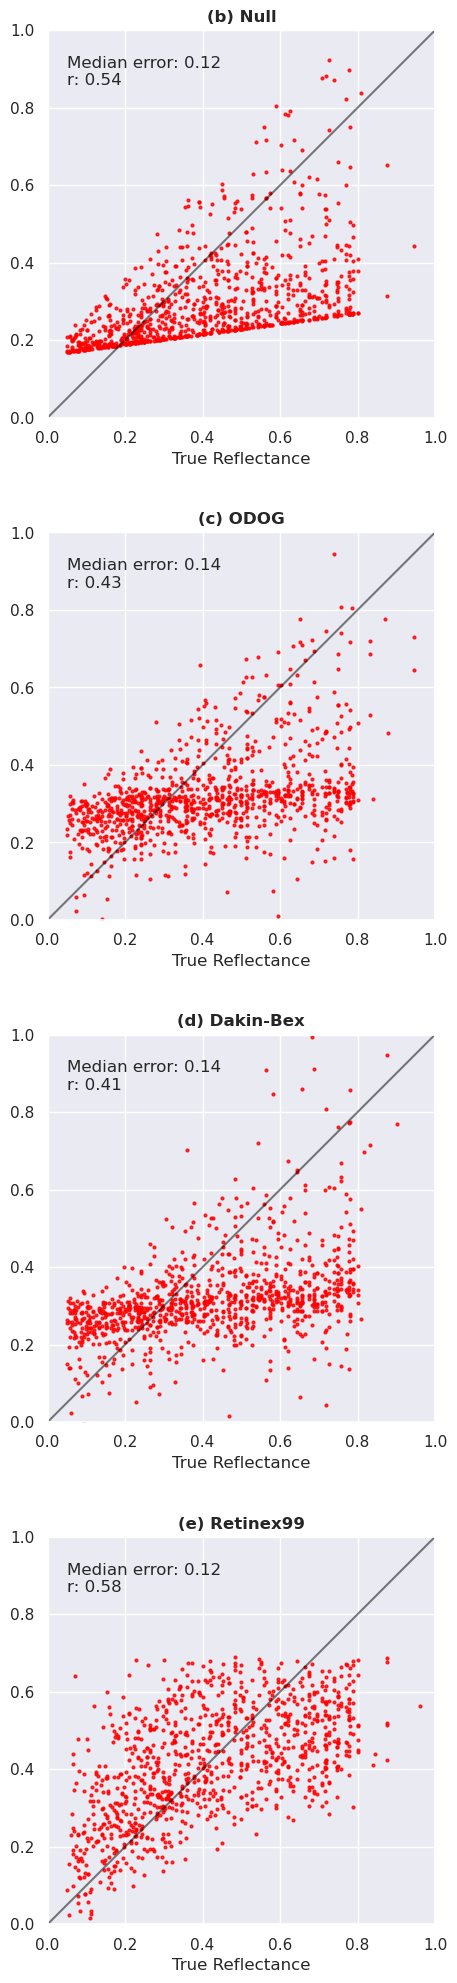

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(4, 1, figsize = (5, 25))

classical_corrs = {'Null': 0.54, 'ODOG': 0.43, 'Dakin-Bex': 0.41, 'Retinex99': 0.58}
classical_mes = {'Null': 0.12, 'ODOG': 0.14, 'Dakin-Bex': 0.14, 'Retinex99': 0.12}

# Define x values for the identity line
x_vals = np.linspace(0, 1, 100)

fig_idx = ['(b)', '(c)', '(d)', '(e)']
for i, filename in enumerate(classical_corrs):

    dat = pd.read_csv(f"scatterplot_{filename}.txt")
    mod_name = filename

    # Plot identity line (ideal predictions)
    ax[i].plot(x_vals, x_vals, color='black', alpha=0.5)

    # Scatterplot the model outputs
    ax[i].scatter(dat['ref'], dat['ref_hat'], color='red', s=4, alpha=0.8)

    # Calculate the correlation and median error
    correlation = np.corrcoef(dat['ref'], dat['ref_hat'])[0, 1]
    median_error = np.median(np.absolute(dat['ref'] - dat['ref_hat']))
    print(f"{filename}: {correlation=:.2f}, {median_error=:.2f}")

    # Labels and limits
    ax[i].set_xlabel('True Reflectance')
    ax[i].set_title(fig_idx[i] + ' ' + mod_name, weight='bold')
    ax[i].set_xlim(0, 1)
    ax[i].set_ylim(0, 1)
    ax[i].set_aspect('equal')

    # Add text annotation with median error and correlation
    ax[i].text(0.05, 0.85, f"Median error: {classical_mes[mod_name]}\nr: {classical_corrs[mod_name]}",
                transform=ax[i].transAxes, fontsize=12, 
                verticalalignment='bottom', horizontalalignment='left')

# plt.suptitle('Reflectance estimation', weight='bold')
plt.show()
